Goals of the notebook:

- Cluster the neurons
- Save out labelmat

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import yaml 
from pathlib import Path 

import numpy as np
import pandas as pd
import scanpy as sc
from dotenv import dotenv_values

from hm3d_utils.clustering import run_decomposition
from hm3d_utils.plotting import zoom_umap

In [3]:
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])
CLUSTERING_DIR = DATADIR / "5_clustering"
MODELDIR = CLUSTERING_DIR / 'all_control'
DATASETS_DIR = MODELDIR / "datasets"


In [4]:
PARAMS_FILE = Path("resources", "clustering_params.yaml")


In [5]:
CELL_TYPE = "Neuro" 

if CELL_TYPE == "Neuro":
    adata_fp = DATASETS_DIR / 'neuronal_raw_embed_propagated.h5ad'
else:
    adata_fp = DATASETS_DIR / 'glial_raw_embed_propagated.h5ad'

In [6]:
with open(PARAMS_FILE, "r") as fp:
            parameters = yaml.safe_load(fp)

parameters

{'loop': {'initial_solution_key': 'L1', 'max_levels': 10},
 'neighbors': {'n_neighbors': 15, 'use_rep': 'X_embed'},
 'leiden': {'n_iterations': 5, 'n_jobs': 20, 'n_seeds': 100, 'resolution': []},
 'consensus': {'random_state': 0},
 'pruning': {'max_stratum_size': 10000,
  'min_stratum_size': 10,
  'min_cluster_size': 100,
  'min_marker_genes': 30,
  'symmetric_intermediate_resolution': True,
  'symmetric_highest_resolution': False,
  'min_pct_expression': 0.1,
  'min_specificity': 0.2,
  'min_strata': 2,
  'nn_checks': 2,
  'random_state': 0,
  'significance_threshold': 0.001,
  'strata_key': 'Sample',
  'use_rep': 'X_embed'},
 'masking': {'enabled': False,
  'min_nn_agreement': 0.5,
  'n_neighbors': 40,
  'use_rep': 'X_embed'}}

In [7]:
adata = sc.read_h5ad(adata_fp, backed="r")

if CELL_TYPE == "Neuro":
    load_mask = adata.obs.IsControl
else:
    load_mask = (adata.obs["major_features_propagated"].str.contains(CELL_TYPE)) & (adata.obs.IsControl)

adata = adata[load_mask].to_memory()

adata.obs["L1"] = adata.obs.major_features_propagated.copy()
# Remove excluded genes
adata = adata[:, ~adata.var.IsHvgExcludedGene]

sc.pp.normalize_total(adata, target_sum=10_000)

/beegfs/home/mfeldmann/repos/HypoMap3D/.venv/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:269: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [8]:
# for later plotting of gene expression
adata.layers["log1p"] = adata.X.copy()
sc.pp.log1p(adata, layer="log1p")

In [9]:
adata

AnnData object with n_obs × n_vars = 630146 × 55371
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'ABC_class_propagated', 'ABC_class_confidence', 'to_be_removed', 'IsNeuronal', 'major_features', 'major_features_propagated', 'major_features_confidence', 'ABC_supertype_propagated', 'ABC_supertype_confidence', 'ABC_subclass_propagated', 'ABC_subclass_confidence', 'ABC_cluster_propagated', 'ABC_cluster_confidence', 'L1'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    uns: 'neighbors', 'tsne', 'umap', 'log1p

## Decomposing L1

In [10]:
l1_labelmats = {}

for res in [0.37]: 

    labelmat = run_decomposition(
        adata,
        use_rep = parameters["neighbors"]["use_rep"],
        init_key = parameters["loop"]["initial_solution_key"],
        max_levels = 1,
        n_neighbors = parameters["neighbors"]["n_neighbors"],
        resolutions = [res],
        n_seeds = parameters["leiden"]["n_seeds"],
        n_iterations = parameters["leiden"]["n_iterations"],
        n_jobs = parameters["leiden"]["n_jobs"],
        strata_key = parameters["pruning"]["strata_key"],
        nn_checks = parameters["pruning"]["nn_checks"],
        min_cluster_size = parameters["pruning"]["min_cluster_size"],
        min_stratum_size = parameters["pruning"]["min_stratum_size"],
        max_stratum_size = parameters["pruning"]["max_stratum_size"],
        min_strata = parameters["pruning"]["min_strata"],
        min_pct_expression = parameters["pruning"]["min_pct_expression"],
        min_specificity = parameters["pruning"]["min_specificity"],
        significance_threshold = parameters["pruning"]["significance_threshold"],
        min_marker_genes = parameters["pruning"]["min_marker_genes"],
        symmetric = parameters["pruning"]["symmetric_intermediate_resolution"],
        masking_enabled = parameters["masking"]["enabled"],
        min_nn_agreement = parameters["masking"]["min_nn_agreement"],
        random_state = parameters["pruning"]["random_state"]
    )

    labelmat = pd.Series(labelmat[:, -1], index=adata.obs.index).replace('-1', pd.NA).astype("category")

    l1_labelmats[res] = labelmat

    adata.obs[f"L2_new_{res}"] = labelmat


29 vs 40 passed with 126 vs 300 markers
2 vs 10 passed with 82 vs 189 markers
27 vs 32 passed with 143 vs 137 markers
6 vs 26 passed with 331 vs 174 markers
7 vs 20 passed with 203 vs 236 markers
11 vs 12 passed with 210 vs 175 markers
21 vs 23 passed with 394 vs 123 markers
6 vs 36 passed with 537 vs 137 markers
10 vs 30 passed with 160 vs 178 markers
26 vs 37 passed with 292 vs 139 markers
24 vs 30 passed with 155 vs 257 markers
22 vs 40 passed with 539 vs 263 markers
22 vs 29 passed with 839 vs 189 markers
10 vs 24 passed with 249 vs 188 markers
7 vs 17 passed with 80 vs 191 markers
14 vs 25 passed with 665 vs 349 markers
17 vs 22 passed with 247 vs 72 markers
17 vs 28 passed with 246 vs 141 markers
37 vs 39 passed with 197 vs 226 markers
4 vs 39 passed with 316 vs 497 markers
15 vs 37 passed with 223 vs 146 markers
19 vs 20 passed with 343 vs 386 markers
12 vs 22 passed with 251 vs 250 markers
16 vs 39 passed with 677 vs 241 markers
6 vs 34 passed with 469 vs 128 markers
17 vs 19 p

In [11]:
final_l2_col = "L2_new_0.37"

## Decomposing L2

In [12]:

for res in [0.13]: 

    labelmat = run_decomposition(
        adata,
        use_rep = parameters["neighbors"]["use_rep"],
        init_key = final_l2_col,
        max_levels = 2,
        n_neighbors = parameters["neighbors"]["n_neighbors"],
        resolutions = [res],
        n_seeds = parameters["leiden"]["n_seeds"],
        n_iterations = parameters["leiden"]["n_iterations"],
        n_jobs = parameters["leiden"]["n_jobs"],
        strata_key = parameters["pruning"]["strata_key"],
        nn_checks = parameters["pruning"]["nn_checks"],
        min_cluster_size = parameters["pruning"]["min_cluster_size"],
        min_stratum_size = parameters["pruning"]["min_stratum_size"],
        max_stratum_size = parameters["pruning"]["max_stratum_size"],
        min_strata = parameters["pruning"]["min_strata"],
        min_pct_expression = parameters["pruning"]["min_pct_expression"],
        min_specificity = parameters["pruning"]["min_specificity"],
        significance_threshold = parameters["pruning"]["significance_threshold"],
        min_marker_genes = parameters["pruning"]["min_marker_genes"],
        symmetric = parameters["pruning"]["symmetric_intermediate_resolution"],
        masking_enabled = parameters["masking"]["enabled"],
        min_nn_agreement = parameters["masking"]["min_nn_agreement"],
        random_state = parameters["pruning"]["random_state"],
        level=1 # start at level idx 1 as you have decomposed the 0th level before
    )

    labelmat = pd.Series(labelmat[:, -1], index=adata.obs.index).replace('-1', pd.NA).astype("category")

    adata.obs[f"L3_new_{res}"] = labelmat


1 vs 2 passed with 371 vs 266 markers
0 vs 2 passed with 439 vs 333 markers
0 vs 1 passed with 337 vs 336 markers
1 vs 2 passed with 65 vs 67 markers
1 vs 3 passed with 57 vs 127 markers
0 vs 3 passed with 175 vs 285 markers
2 vs 3 passed with 105 vs 158 markers
0 vs 1 passed with 216 vs 209 markers
0 vs 2 passed with 42 vs 292 markers
1 vs 2 passed with 105 vs 142 markers
0 vs 1 passed with 85 vs 479 markers
0 vs 1 passed with 145 vs 118 markers
1 vs 2 passed with 229 vs 173 markers
0 vs 2 passed with 184 vs 123 markers
3 vs 4 passed with 176 vs 110 markers
2 vs 4 passed with 105 vs 252 markers
1 vs 3 passed with 124 vs 344 markers
0 vs 2 passed with 220 vs 115 markers
1 vs 2 passed with 237 vs 137 markers
0 vs 3 passed with 149 vs 167 markers
1 vs 3 passed with 145 vs 223 markers
1 vs 2 passed with 161 vs 164 markers
0 vs 3 passed with 135 vs 190 markers
2 vs 3 passed with 154 vs 341 markers
0 vs 2 passed with 176 vs 106 markers
1 vs 3 passed with 144 vs 330 markers
1 vs 2 passed wit

In [13]:
final_l3_col = "L3_new_0.13"

## Decomposing L3

In [14]:
for res in [[0.2, 0.3, 0.4, 0.5, 1]]: 

    labelmat = run_decomposition(
        adata,
        use_rep = parameters["neighbors"]["use_rep"],
        init_key = final_l3_col,
        max_levels = 10,
        n_neighbors = parameters["neighbors"]["n_neighbors"],
        resolutions = res if isinstance(res, list) else [res],
        n_seeds = parameters["leiden"]["n_seeds"],
        n_iterations = parameters["leiden"]["n_iterations"],
        n_jobs = parameters["leiden"]["n_jobs"],
        strata_key = parameters["pruning"]["strata_key"],
        nn_checks = parameters["pruning"]["nn_checks"],
        min_cluster_size = parameters["pruning"]["min_cluster_size"],
        min_stratum_size = parameters["pruning"]["min_stratum_size"],
        max_stratum_size = parameters["pruning"]["max_stratum_size"],
        min_strata = parameters["pruning"]["min_strata"],
        min_pct_expression = parameters["pruning"]["min_pct_expression"],
        min_specificity = parameters["pruning"]["min_specificity"],
        significance_threshold = parameters["pruning"]["significance_threshold"],
        min_marker_genes = parameters["pruning"]["min_marker_genes"],
        symmetric = parameters["pruning"]["symmetric_intermediate_resolution"],
        masking_enabled = parameters["masking"]["enabled"],
        min_nn_agreement = parameters["masking"]["min_nn_agreement"],
        random_state = parameters["pruning"]["random_state"],
        level=2 # start at level idx 1 as you have decomposed the 0th level before
    )

    labelmat = pd.Series(labelmat[:, -1], index=adata.obs.index).replace('-1', pd.NA).astype("category")

    adata.obs[f"L4_new_{res}"] = labelmat

1 vs 2 passed with 111 vs 114 markers
0 vs 1 passed with 174 vs 74 markers
0 vs 2 passed with 312 vs 147 markers
0 or 3 merged due to insufficient cluster size 625/16.
	>>3 and 0 merged to make 3_0
1 vs 3_0 passed with 75 vs 172 markers
2 vs 3_0 passed with 151 vs 308 markers
2 vs 5 passed with 54 vs 32 markers
1 vs 2 passed with 34 vs 98 markers
0 vs 4 passed with 46 vs 48 markers
2 vs 4 passed with 40 vs 73 markers
3 vs 4 passed with 41 vs 119 markers
1 vs 5 passed with 51 vs 75 markers
1 vs 3 passed with 57 vs 94 markers
0 vs 5 passed with 97 vs 33 markers
1 vs 4 passed with 59 vs 37 markers
0 vs 4 FAILED with 22 vs 5 markers
	>>4 and 0 merged to make 4_0
1 vs 4_0 passed with 67 vs 66 markers
5 vs 4_0 passed with 78 vs 76 markers
2 vs 4_0 FAILED with 8 vs 0 markers
	>>4_0 and 2 merged to make 4_0_2
1 vs 4_0_2 passed with 68 vs 69 markers
5 vs 4_0_2 passed with 68 vs 87 markers
1 vs 5 passed with 129 vs 98 markers
3 vs 4_0_2 passed with 56 vs 95 markers
1 vs 3 passed with 90 vs 40 ma

In [15]:
final_l4_col = "L4_new_[0.2, 0.3, 0.4, 0.5, 1]"

## Decomposing L4

In [16]:

for res in [[0.2, 0.3, 0.4, 0.5, 1]]: 

    labelmat = run_decomposition(
        adata,
        use_rep = parameters["neighbors"]["use_rep"],
        init_key = final_l4_col,
        max_levels = 20,
        n_neighbors = parameters["neighbors"]["n_neighbors"],
        resolutions = res if isinstance(res, list) else [res],
        n_seeds = parameters["leiden"]["n_seeds"],
        n_iterations = parameters["leiden"]["n_iterations"],
        n_jobs = parameters["leiden"]["n_jobs"],
        strata_key = parameters["pruning"]["strata_key"],
        nn_checks = parameters["pruning"]["nn_checks"],
        min_cluster_size = parameters["pruning"]["min_cluster_size"],
        min_stratum_size = parameters["pruning"]["min_stratum_size"],
        max_stratum_size = parameters["pruning"]["max_stratum_size"],
        min_strata = parameters["pruning"]["min_strata"],
        min_pct_expression = parameters["pruning"]["min_pct_expression"],
        min_specificity = parameters["pruning"]["min_specificity"],
        significance_threshold = parameters["pruning"]["significance_threshold"],
        min_marker_genes = parameters["pruning"]["min_marker_genes"],
        symmetric = parameters["pruning"]["symmetric_highest_resolution"], # allowing asymmetric marker genes during pruning
        masking_enabled = parameters["masking"]["enabled"],
        min_nn_agreement = parameters["masking"]["min_nn_agreement"],
        random_state = parameters["pruning"]["random_state"],
        level=11 # start at level idx 1 as you have decomposed the 0th level before
    )

    labelmat = pd.Series(labelmat[:, -1], index=adata.obs.index).replace('-1', pd.NA).astype("category")

    adata.obs[f"L5_new_{res}"] = labelmat


1 or 3 merged due to insufficient cluster size 58/59.
	>>3 and 1 merged to make 3_1
2 or 6 merged due to insufficient cluster size 57/38.
	>>6 and 2 merged to make 6_2
0 or 6_2 merged due to insufficient cluster size 50/95.
	>>6_2 and 0 merged to make 6_2_0
5 or 3_1 merged due to insufficient cluster size 68/117.
	>>3_1 and 5 merged to make 3_1_5
6_2_0 and 3_1_5 merged due to insufficient valid overlapping strata.
	>>3_1_5 and 6_2_0 merged to make 3_1_5_6_2_0
4 or 3_1_5_6_2_0 merged due to insufficient cluster size 46/330.
	>>3_1_5_6_2_0 and 4 merged to make 3_1_5_6_2_0_4
3 or 4 merged due to insufficient cluster size 92/75.
	>>4 and 3 merged to make 4_3
1 or 4_3 merged due to insufficient cluster size 85/167.
	>>4_3 and 1 merged to make 4_3_1
2 or 4_3_1 merged due to insufficient cluster size 50/252.
	>>4_3_1 and 2 merged to make 4_3_1_2
0 or 5 merged due to insufficient cluster size 45/86.
	>>5 and 0 merged to make 5_0
6 and 5_0 merged due to insufficient valid overlapping strata.
	>

2 or 3 merged due to insufficient cluster size 55/71.
	>>3 and 2 merged to make 3_2
1 or 6 merged due to insufficient cluster size 86/87.
	>>6 and 1 merged to make 6_1
3_2 and 6_1 merged due to insufficient valid overlapping strata.
	>>6_1 and 3_2 merged to make 6_1_3_2
0 and 5 merged due to insufficient valid overlapping strata.
	>>5 and 0 merged to make 5_0
4 or 5_0 merged due to insufficient cluster size 79/244.
	>>5_0 and 4 merged to make 5_0_4
6_1_3_2 and 5_0_4 merged due to insufficient valid overlapping strata.
	>>5_0_4 and 6_1_3_2 merged to make 5_0_4_6_1_3_2
1 and 6 merged due to insufficient valid overlapping strata.
	>>6 and 1 merged to make 6_1
3 and 7 merged due to insufficient valid overlapping strata.
	>>7 and 3 merged to make 7_3
6_1 vs 7_3 FAILED with 2 markers
	>>7_3 and 6_1 merged to make 7_3_6_1
8 or 9 merged due to insufficient cluster size 212/90.
	>>9 and 8 merged to make 9_8
4 or 9_8 merged due to insufficient cluster size 96/302.
	>>9_8 and 4 merged to make 9_8

In [17]:
final_l5_col = "L5_new_[0.2, 0.3, 0.4, 0.5, 1]"

When checking some of our clusters we realized that the Gnrh1 cluster included some low-quality cells scattered across the Umap.

These cells also did not express Gnrh1.

Hence, we decided to remove those suspected low-quality cells from the Gnrh1 cluster.

Unfortunately, those low-quality cells also did not split at higher resolutions, so we removed them using a dummy clustering.

In [18]:
adata.obs["expresses_gnrh1"] = adata[:, "Gnrh1"].X.toarray() > 0 

/tmp/ipykernel_681992/102349292.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  gnrh_cluster = adata.obs[[final_l2_col, "expresses_gnrh1"]].groupby(final_l2_col)["expresses_gnrh1"].mean().idxmax()


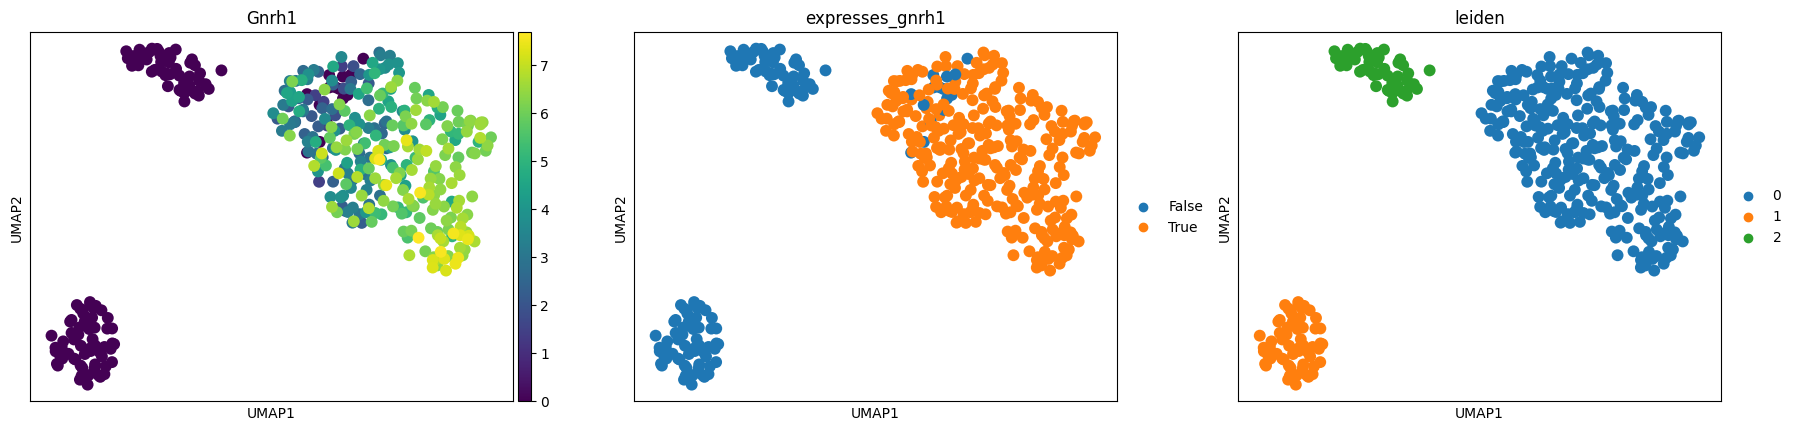

In [21]:
gnrh_cluster = adata.obs[[final_l2_col, "expresses_gnrh1"]].groupby(final_l2_col)["expresses_gnrh1"].mean().idxmax()

gnrh = adata[adata.obs[final_l2_col]==gnrh_cluster].copy()

sc.pp.neighbors(gnrh, n_neighbors=15, use_rep="X_embed")
sc.tl.umap(gnrh)
sc.tl.leiden(gnrh, resolution=0.2, flavor="igraph")

sc.pl.umap(gnrh, color=[ "Gnrh1", "expresses_gnrh1", "leiden"], ncols=3, layer="log1p")

In [22]:
remove_cells = gnrh[gnrh.obs.leiden != "0"].obs_names

In [23]:
for i in range(1,6):
    adata.obs.loc[remove_cells, f"L{i}"] = np.nan

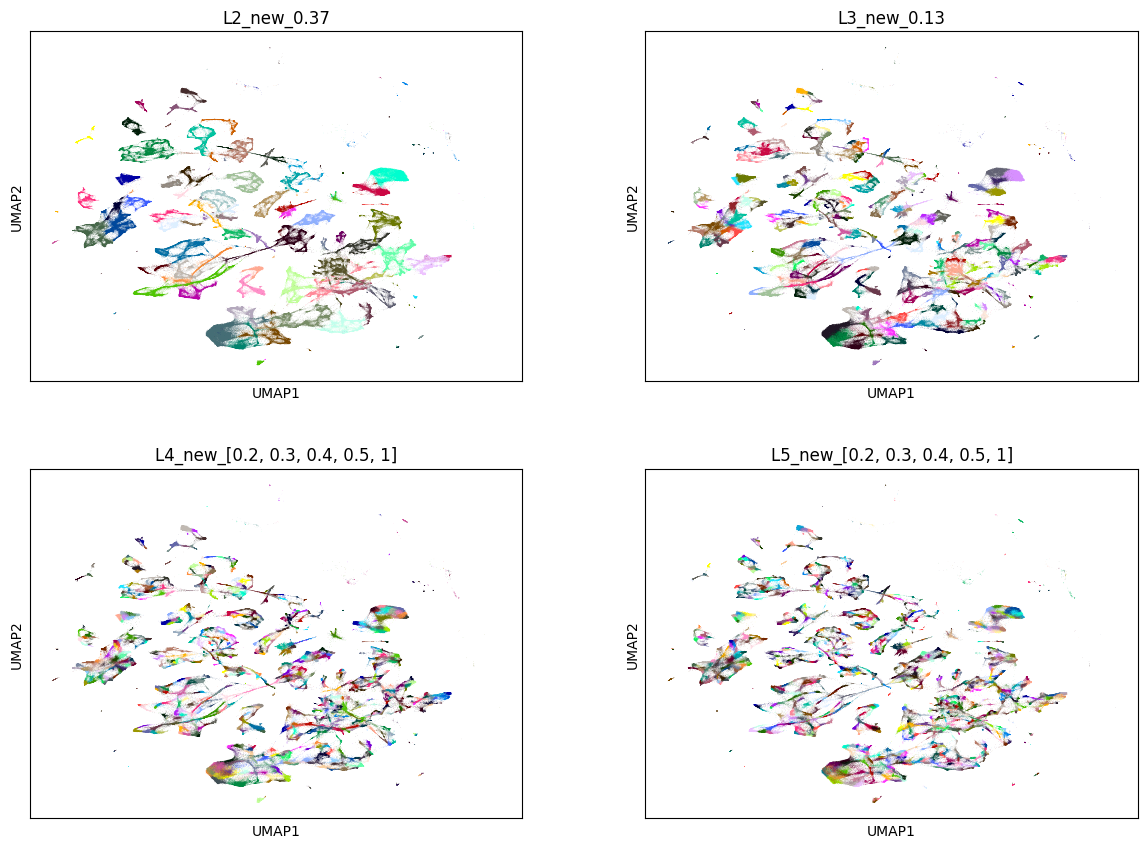

In [24]:
sc.pl.umap(adata, color=[final_l2_col, final_l3_col, final_l4_col, final_l5_col], ncols=2, legend_loc=None,palette=sc.pl.palettes.default_102, )

### Let's save out our labels

In [25]:
final_labelmat = adata.obs.loc[:, ["major_features_propagated", final_l2_col, final_l3_col, final_l4_col, final_l5_col]]
final_labelmat.columns = [f"L{i}" for i in range(1,6)]

In [26]:
final_labelmat

,L1,L2,L3,L4,L5
SC1-01_SAMN18754353_AAACCCACAACCAGAG,Glut,405,10009,2305238946,2305238946
SC1-01_SAMN18754353_AAACCCAGTCATCTAG,Glut,61775,97018,10426458,113469568
SC1-01_SAMN18754353_AAACGAAAGCAAGCCA,Glut,405,7748,16105647,16105647
SC1-01_SAMN18754353_AAACGAAGTGCGGCTT,Glut,405,10009,2602618,2602618
SC1-01_SAMN18754353_AAACGAATCGCATAGT,Glut,405,5884,73150557,11359749
...,...,...,...,...,...
SC2-25_SAMN46505609_TTTGTTGGTCACTCGC,GABA,21944,1277599,12273532,2256206713
SC2-25_SAMN46505609_TTTGTTGGTGCGCGTA,Glut,304589,494,494,24741
SC2-25_SAMN46505609_TTTGTTGGTGGGTGAA,Glut,82620,27728,20772232,21570371944
SC2-25_SAMN46505609_TTTGTTGGTGTTTGAG,Glut,61775,62479,371785543,371785543


In [ ]:
for i in range(1,6):
    final_labelmat[f"L{i}"] = final_labelmat[f"L{i}"].astype("category")
    
#final_labelmat.to_csv(CLUSTERING_DIR / 'neuron_labelmat.csv')